# Tiểu luận Lập trình Python - Nhóm 1 - Đề tài 2

## Huấn luyện, đánh giá và lưu mô hình dự đoán nguy cơ bệnh tim mạch

Notebook này nối tiếp bài nghiệm thu `TeamWork_PP_Nhom1.ipynb`: dùng cùng dữ liệu đã làm sạch (68.539 mẫu, 10 đặc trưng), cùng cách chia train/test và cùng 3 mô hình đã chọn ở mục 3 của bài nghiệm thu.

| STT | Họ và tên | MSSV |
|---|---|---|
| 1 | Nguyễn Minh Toàn (nhóm trưởng) | 23150145 |
| 2 | Đỗ Anh Tùng | 25150012 |
| 3 | Nguyễn Anh Đức | 25280017 |

**Các bước**
1. Đọc dữ liệu và chia train/test
2. Kiểm định chéo 3 mô hình với tham số mặc định
3. Tinh chỉnh siêu tham số
4. Chọn mô hình
5. Chọn ngưỡng cảnh báo
6. Đánh giá trên tập test
7. Kiểm tra overfitting
8. Feature Importance
9. Kiểm tra xác suất dự đoán (calibration)
10. Kiểm tra hướng tác động (ràng buộc đơn điệu)
11. Lưu mô hình cho ứng dụng

In [ ]:
import io
import json
import sys
import time
from datetime import date
from pathlib import Path
from typing import Dict

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.calibration import CalibrationDisplay
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             brier_score_loss, classification_report, confusion_matrix,
                             f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Thư mục gốc của dự án: notebook nằm trong notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.preprocessing import FEATURES, TARGET, load_clean_dataset  # noqa: E402

RANDOM_STATE = 42
# Ràng buộc đơn điệu cho 2 mô hình cây từ bước tinh chỉnh (mục 3), theo y khoa:
# 1 = chỉ số tăng thì nguy cơ không giảm, -1 = chỉ số tăng thì nguy cơ không tăng,
# 0 = không ràng buộc (giới tính)
MONOTONIC = {"age_years": 1, "gender": 0, "bmi": 1, "ap_hi": 1, "ap_lo": 1,
             "cholesterol": 1, "gluc": 1, "smoke": 1, "alco": 1, "active": -1}
MONOTONIC_CST = [MONOTONIC[name] for name in FEATURES]
MODEL_DIR = ROOT / "models"
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
METRIC_NAMES = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
                "f1": "F1", "roc_auc": "ROC-AUC"}

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.7.2


## 1. Đọc dữ liệu và chia train/test

Hàm `load_clean_dataset` trong `src/preprocessing.py` làm lại các bước của bài nghiệm thu: xóa 24 dòng trùng, xóa 1.437 dòng có giá trị sai, tạo `age_years`, `bmi`, mã hóa `gender`. Ứng dụng demo cũng gọi các hàm này để xử lý số liệu người dùng nhập.

In [ ]:
df, clean_report = load_clean_dataset([ROOT / "data" / "cardio_train.csv"])
print(pd.Series(clean_report).to_string())

X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"\nTrain: {len(X_train):,} mẫu ({y_train.mean():.2%} có bệnh)")
print(f"Test:  {len(X_test):,} mẫu ({y_test.mean():.2%} có bệnh)")

dòng gốc                    70000
dòng trùng                     24
ap_hi ngoài 70-250            229
ap_lo ngoài 40-160           1025
height ngoài 130-210           93
weight ngoài 35-200            20
ap_lo >= ap_hi               1236
dòng sai (ít nhất 1 lỗi)     1437
dòng còn lại                68539

Train: 54,831 mẫu (49.48% có bệnh)
Test:  13,708 mẫu (49.48% có bệnh)


Số dòng và cách chia trùng với bài nghiệm thu: 68.539 mẫu, train 54.831, test 13.708, tỷ lệ có bệnh 49,48% ở cả hai tập. Từ đây đến mục 5, nhóm chỉ dùng tập train; tập test để dành cho mục 6.

## 2. Kiểm định chéo với tham số mặc định

Mỗi mô hình được huấn luyện 5 lần trên tập train theo `StratifiedKFold` (5 fold). Mỗi lần, 4 fold dùng để học và 1 fold dùng để chấm điểm. Cột "F1 (train)" là điểm trên chính phần dữ liệu mô hình đã học; nếu cột này cao hơn nhiều so với cột F1 thì mô hình đang học thuộc dữ liệu (overfitting).

In [ ]:
def cv_table(models: Dict[str, object]) -> pd.DataFrame:
    """Kiểm định chéo 5 fold trên tập train cho từng mô hình.

    Args:
        models: tên mô hình -> mô hình chưa huấn luyện.

    Returns:
        Bảng trung bình 5 fold của mỗi metric, F1 trên phần train và thời gian chạy.
    """
    rows = {}
    for name, model in models.items():
        start = time.perf_counter()
        result = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING,
                                return_train_score=True, n_jobs=-1)
        row = {METRIC_NAMES[key]: result[f"test_{key}"].mean() for key in SCORING}
        row["F1 (train)"] = result["train_f1"].mean()
        row["Thời gian (s)"] = time.perf_counter() - start
        rows[name] = row
    return pd.DataFrame(rows).T


baseline_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
baseline = cv_table(baseline_models)
baseline.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,F1 (train),Thời gian (s)
Logistic Regression,0.7277,0.7544,0.6667,0.7078,0.7910,0.7078,3.3166
Random Forest,0.6972,0.6955,0.6901,0.6928,0.7542,0.9869,19.2369
Gradient Boosting,0.7351,0.7550,0.6881,0.7199,0.8000,0.7294,2.4444


**Nhận xét:** với tham số mặc định, Gradient Boosting có F1 (0,7199) và ROC-AUC (0,8000) cao nhất, Logistic Regression đứng thứ hai (F1 0,7078). Random Forest mặc định kém nhất (F1 0,6928) dù là mô hình phức tạp nhất. F1 trên phần train của Random Forest là 0,9869, cao hơn F1 kiểm định chéo gần 30 điểm phần trăm. Mặc định, mỗi cây của Random Forest mọc không giới hạn độ sâu và mỗi lá chỉ cần 1 mẫu (`max_depth=None`, `min_samples_leaf=1`), nên mô hình học thuộc cả nhiễu trong dữ liệu (overfitting).

Logistic Regression có F1 train và F1 kiểm định chéo bằng nhau (0,7078): mô hình không overfit, nhưng cũng không học được quan hệ phi tuyến. Cả ba mô hình có Recall dưới 0,70, tức ở ngưỡng 0,5 mô hình bỏ sót hơn 30% người có bệnh.

## 3. Tinh chỉnh siêu tham số

Nhóm thử nhiều bộ siêu tham số cho mỗi mô hình, chấm mỗi bộ bằng kiểm định chéo 5 fold và giữ bộ có **F1 trung bình cao nhất** (`refit="f1"`).

- Logistic Regression chỉ có 5 giá trị `C` (độ mạnh của regularization, `C` càng nhỏ thì phạt hệ số càng mạnh), nên nhóm thử hết bằng `GridSearchCV`.
- Random Forest có 96 tổ hợp và Gradient Boosting có 729 tổ hợp. Thử hết sẽ mất nhiều giờ, nên nhóm dùng `RandomizedSearchCV`: chọn ngẫu nhiên 12 tổ hợp cho Random Forest và 20 tổ hợp cho Gradient Boosting (mô hình này huấn luyện nhanh hơn).
- Từ bước này, hai mô hình cây có thêm **ràng buộc đơn điệu** (`monotonic_cst`, biến `MONOTONIC` ở ô đầu). Khi tuổi, BMI, huyết áp, cholesterol, đường huyết, hút thuốc hoặc rượu bia tăng, xác suất có bệnh không được giảm. Vận động thì ngược lại, còn giới tính không bị ràng buộc. Mô hình chỉ học tương quan, nên nếu không ràng buộc, bảng "Nếu cải thiện chỉ số" của ứng dụng có thể báo chỉ số tốt lên mà nguy cơ lại tăng (kiểm tra ở mục 10). Logistic Regression là mô hình tuyến tính, không có tham số này.
- `max_depth`, `min_samples_leaf`, `max_leaf_nodes` giới hạn độ phức tạp của cây để giảm overfitting. `l2_regularization` phạt các lá có giá trị lớn. Gradient Boosting tự dừng sớm (early stopping) khi điểm trên 10% dữ liệu kiểm tra nội bộ không tăng nữa, nên `max_iter` là số cây tối đa.

In [ ]:
search_spaces = {
    "Logistic Regression": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
        None,
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, monotonic_cst=MONOTONIC_CST),
        {"n_estimators": [200, 300], "max_depth": [8, 12, 16, None],
         "min_samples_leaf": [10, 20, 50, 100], "max_features": ["sqrt", 0.5, 1.0]},
        12,
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE, monotonic_cst=MONOTONIC_CST),
        {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [100, 200, 300],
         "max_leaf_nodes": [15, 31, 63], "max_depth": [None, 4, 6],
         "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 0.5, 1.0]},
        20,
    ),
}

searches = {}
for name, (model, grid, n_iter) in search_spaces.items():
    n_combos = int(np.prod([len(values) for values in grid.values()]))
    common = dict(scoring=SCORING, refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
    if n_iter is None:
        search = GridSearchCV(model, grid, **common)
    else:
        search = RandomizedSearchCV(model, grid, n_iter=n_iter,
                                    random_state=RANDOM_STATE, **common)
    start = time.perf_counter()
    search.fit(X_train, y_train)
    searches[name] = search
    tried = len(search.cv_results_["params"])
    print(f"{name}: thử {tried}/{n_combos} tổ hợp x 5 fold, "
          f"{time.perf_counter() - start:.0f} giây")

Logistic Regression: thử 5/5 tổ hợp x 5 fold, 2 giây


Random Forest: thử 12/96 tổ hợp x 5 fold, 205 giây


Gradient Boosting: thử 20/729 tổ hợp x 5 fold, 72 giây


In [ ]:
def best_cv_row(search) -> Dict[str, float]:
    """Lấy điểm kiểm định chéo của bộ siêu tham số tốt nhất trong một lần search."""
    i, res = search.best_index_, search.cv_results_
    row = {METRIC_NAMES[key]: res[f"mean_test_{key}"][i] for key in SCORING}
    row["F1 (train)"] = res["mean_train_f1"][i]
    return row


tuned = pd.DataFrame({name: best_cv_row(s) for name, s in searches.items()}).T
display(tuned.round(4))

for name, search in searches.items():
    print(f"{name}: {search.best_params_}")

pd.DataFrame({
    "F1 mặc định": baseline["F1"], "F1 sau tinh chỉnh": tuned["F1"],
    "Recall mặc định": baseline["Recall"], "Recall sau tinh chỉnh": tuned["Recall"],
    "F1 (train) mặc định": baseline["F1 (train)"],
    "F1 (train) sau tinh chỉnh": tuned["F1 (train)"],
}).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,F1 (train)
Logistic Regression,0.7277,0.7544,0.6667,0.7078,0.7910,0.7078
Random Forest,0.7206,0.7315,0.6879,0.7090,0.7851,0.7084
Gradient Boosting,0.7340,0.7541,0.6863,0.7186,0.7983,0.7207


Logistic Regression: {'logisticregression__C': 1}
Random Forest: {'n_estimators': 300, 'min_samples_leaf': 50, 'max_features': 1.0, 'max_depth': 16}
Gradient Boosting: {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 100, 'max_depth': 6, 'learning_rate': 0.1, 'l2_regularization': 1.0}


,F1 mặc định,F1 sau tinh chỉnh,Recall mặc định,Recall sau tinh chỉnh,F1 (train) mặc định,F1 (train) sau tinh chỉnh
Logistic Regression,0.7078,0.7078,0.6667,0.6667,0.7078,0.7078
Random Forest,0.6928,0.7090,0.6901,0.6879,0.9869,0.7084
Gradient Boosting,0.7199,0.7186,0.6881,0.6863,0.7294,0.7207


**Nhận xét:**

- Random Forest được lợi nhiều nhất: F1 kiểm định chéo tăng từ 0,6928 lên 0,7090, F1 train giảm từ 0,9869 xuống 0,7084. Bộ tham số tốt nhất có `min_samples_leaf=50`: mỗi lá phải có ít nhất 50 mẫu, nên cây không học thuộc từng mẫu được nữa. Ràng buộc đơn điệu cũng hạn chế cách cây chia nhánh, nên giảm overfitting thêm.
- Gradient Boosting giảm nhẹ từ 0,7199 xuống 0,7186 (0,13 điểm phần trăm). Đây là cái giá của ràng buộc đơn điệu: mô hình không được học những quan hệ ngược hướng y khoa có trong dữ liệu. Mục 10 cho thấy cái giá này nhỏ so với lợi ích.
- Logistic Regression giữ nguyên: 5 giá trị `C` cho F1 từ 0,7070 đến 0,7078, giá trị tốt nhất `C=1` cũng là mặc định. Với 54.831 mẫu và 10 đặc trưng, regularization gần như không ảnh hưởng.
- Sau tinh chỉnh, Gradient Boosting dẫn đầu với F1 0,7186 và ROC-AUC 0,7983. Random Forest đạt F1 0,7090 và ROC-AUC 0,7851.

## 4. Chọn mô hình

Quy tắc đã nêu ở mục 3.3 của bài nghiệm thu: chọn mô hình có F1 kiểm định chéo cao nhất; nếu các mô hình chênh nhau dưới 1 điểm phần trăm thì chọn mô hình dễ giải thích hơn. Random Forest và Gradient Boosting khó giải thích ngang nhau. Nếu hai mô hình này hòa, nhóm xét thêm kích thước file và thời gian dự đoán, vì ứng dụng demo phải nạp và chạy mô hình mỗi lần người dùng bấm nút.

In [ ]:
fitted = {name: search.best_estimator_ for name, search in searches.items()}


def model_cost(model) -> Dict[str, float]:
    """Đo kích thước file (MB, nén mức 3) và thời gian dự đoán cả tập test (ms)."""
    buffer = io.BytesIO()
    joblib.dump(model, buffer, compress=3)
    start = time.perf_counter()
    model.predict_proba(X_test)
    return {"File (MB)": buffer.getbuffer().nbytes / 2**20,
            "Dự đoán 13.708 mẫu (ms)": (time.perf_counter() - start) * 1000}


EASE_RANK = {"Logistic Regression": 1, "Random Forest": 2, "Gradient Boosting": 2}  # 1 = dễ nhất
selection = tuned[["F1", "Recall", "ROC-AUC"]].copy()
selection["Cách F1 cao nhất (điểm %)"] = (tuned["F1"].max() - tuned["F1"]) * 100
selection["Độ khó giải thích"] = pd.Series(EASE_RANK)
selection = selection.join(pd.DataFrame({n: model_cost(m) for n, m in fitted.items()}).T)

candidates = selection[selection["Cách F1 cao nhất (điểm %)"] < 1.0]
CHOSEN = candidates.sort_values(["Độ khó giải thích", "File (MB)"]).index[0]
display(selection.round(4))
print(f"Trong vòng 1 điểm % F1: {list(candidates.index)}")
print(f"Mô hình được chọn: {CHOSEN}")
best_model = fitted[CHOSEN]

,F1,Recall,ROC-AUC,Cách F1 cao nhất (điểm %),Độ khó giải thích,File (MB),Dự đoán 13.708 mẫu (ms)
Logistic Regression,0.7078,0.6667,0.7910,1.0746,1,0.0012,4.2221
Random Forest,0.7090,0.6879,0.7851,0.9560,2,2.1583,266.4391
Gradient Boosting,0.7186,0.6863,0.7983,0.0000,2,0.1168,59.1613


Trong vòng 1 điểm % F1: ['Random Forest', 'Gradient Boosting']
Mô hình được chọn: Gradient Boosting


**Nhận xét:** Random Forest thấp hơn Gradient Boosting 0,96 điểm phần trăm F1, vẫn nằm trong ngưỡng hòa 1 điểm. Logistic Regression thấp hơn 1,07 điểm nên bị loại dù dễ giải thích nhất. Giữa hai mô hình cây, file Gradient Boosting nhỏ hơn khoảng 18 lần (0,12 MB so với 2,16 MB) và dự đoán nhanh hơn khoảng 4 lần. Nhóm chọn **Gradient Boosting** (`HistGradientBoostingClassifier`) cho ứng dụng; file nhỏ cũng dễ đưa lên GitHub.

Bộ tham số của mô hình được chọn: `learning_rate=0.1`, `max_iter=100`, `max_leaf_nodes=63`, `max_depth=6`, `min_samples_leaf=50`, `l2_regularization=1.0`, kèm ràng buộc đơn điệu. Mô hình dừng ở 99 cây (xem `n_trees` ở mục 11).

## 5. Chọn ngưỡng cảnh báo

Mô hình trả về xác suất có bệnh. Mặc định, xác suất từ 0,5 trở lên được tính là "có bệnh". Hạ ngưỡng xuống thì mô hình báo nhiều người hơn: Recall tăng (ít bỏ sót người bệnh) nhưng Precision giảm (nhiều người khỏe bị báo nhầm).

Nhóm chọn ngưỡng có **F1 cao nhất** trên xác suất dự đoán ngoài fold (out-of-fold) của tập train: mỗi mẫu train được dự đoán bởi mô hình chưa từng thấy mẫu đó. Cách này không dùng tập test, nên điểm test ở mục 6 vẫn khách quan.

Ngưỡng có F1 cao nhất (làm tròn 2 chữ số): 0.37


,Accuracy,Precision,Recall,F1,Tỷ lệ bị báo có nguy cơ
0.20,0.5954,0.5523,0.9628,0.7019,0.8626
0.30,0.6822,0.6288,0.8732,0.7311,0.6872
0.35,0.7074,0.6643,0.8261,0.7364,0.6153
0.37,0.7159,0.6799,0.8046,0.7370,0.5856
0.40,0.7242,0.6990,0.7773,0.7361,0.5503
0.45,0.7308,0.7257,0.7331,0.7294,0.4999
0.50,0.7340,0.7540,0.6863,0.7186,0.4503
0.60,0.7230,0.8014,0.5853,0.6765,0.3614


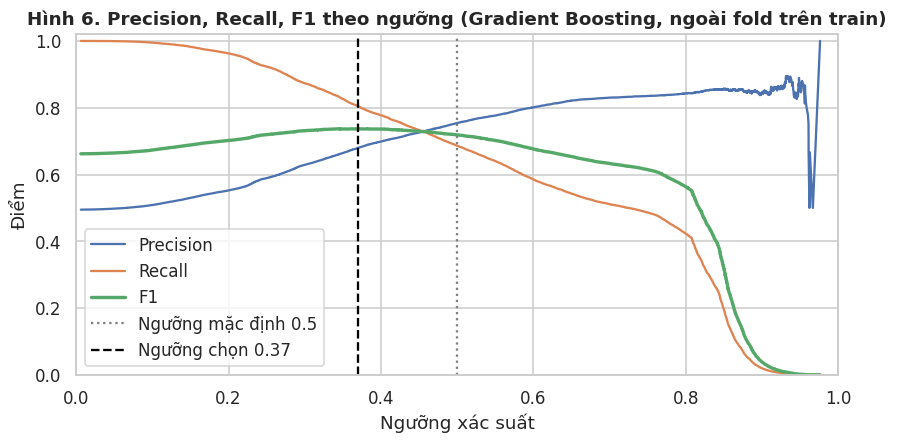

In [ ]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
THRESHOLD = round(float(thresholds[np.argmax(f1_curve)]), 2)
print(f"Ngưỡng có F1 cao nhất (làm tròn 2 chữ số): {THRESHOLD}")


def scores_at(y_true: pd.Series, proba: np.ndarray, threshold: float) -> Dict[str, float]:
    """Tính 5 metric khi coi xác suất >= threshold là có bệnh."""
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "Tỷ lệ bị báo có nguy cơ": pred.mean()}


grid_thresholds = sorted({0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, THRESHOLD})
display(pd.DataFrame({t: scores_at(y_train, oof_proba, t) for t in grid_thresholds}).T.round(4))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(thresholds, precision[:-1], label="Precision")
ax.plot(thresholds, recall[:-1], label="Recall")
ax.plot(thresholds, f1_curve, label="F1", linewidth=2.2)
ax.axvline(0.5, color="grey", linestyle=":", label="Ngưỡng mặc định 0.5")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"Ngưỡng chọn {THRESHOLD}")
ax.set(xlabel="Ngưỡng xác suất", ylabel="Điểm", xlim=(0, 1), ylim=(0, 1.02))
ax.set_title(f"Hình 6. Precision, Recall, F1 theo ngưỡng ({CHOSEN}, ngoài fold trên train)",
             fontweight="bold")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

**Nhận xét:** ngưỡng 0,37 cho F1 cao nhất trên dữ liệu ngoài fold: 0,7370, so với 0,7186 ở ngưỡng 0,5. Ở ngưỡng 0,37, Recall tăng từ 0,6863 lên 0,8046 còn Precision giảm từ 0,7540 xuống 0,6799. Với mỗi 100 người có bệnh, mô hình phát hiện 80 người thay vì 69 người. Đổi lại, tỷ lệ người bị báo có nguy cơ tăng từ 45% lên 59%. Nhóm chấp nhận đánh đổi này vì Recall là metric chính (mục 3.5 của bài nghiệm thu).

Nhóm không hạ ngưỡng thấp hơn nữa. Ở ngưỡng 0,2, Recall đạt 0,96 nhưng 86% số người bị báo có nguy cơ, trong khi chỉ 49,5% thật sự có bệnh, nên cảnh báo mất ý nghĩa.

## 6. Đánh giá trên tập test

Đây là lần đầu tiên nhóm dùng tập test (13.708 mẫu mô hình chưa từng thấy). Ba mô hình đã tinh chỉnh được chấm ở ngưỡng mặc định 0,5; mô hình được chọn được chấm thêm ở ngưỡng đã chọn ở mục 5.

In [ ]:
test_proba = {name: model.predict_proba(X_test)[:, 1] for name, model in fitted.items()}

rows = {}
for name, proba in test_proba.items():
    rows[f"{name} (ngưỡng 0.5)"] = {**scores_at(y_test, proba, 0.5),
                                    "ROC-AUC": roc_auc_score(y_test, proba)}
rows[f"{CHOSEN} (ngưỡng {THRESHOLD})"] = {**scores_at(y_test, test_proba[CHOSEN], THRESHOLD),
                                         "ROC-AUC": roc_auc_score(y_test, test_proba[CHOSEN])}
test_table = pd.DataFrame(rows).T
test_table.round(4)

,Accuracy,Precision,Recall,F1,Tỷ lệ bị báo có nguy cơ,ROC-AUC
Logistic Regression (ngưỡng 0.5),0.7280,0.7555,0.6656,0.7077,0.4359,0.7922
Random Forest (ngưỡng 0.5),0.7199,0.7329,0.6829,0.7070,0.4610,0.7863
Gradient Boosting (ngưỡng 0.5),0.7345,0.7538,0.6882,0.7195,0.4518,0.8000
Gradient Boosting (ngưỡng 0.37),0.7140,0.6764,0.8091,0.7368,0.5918,0.8000


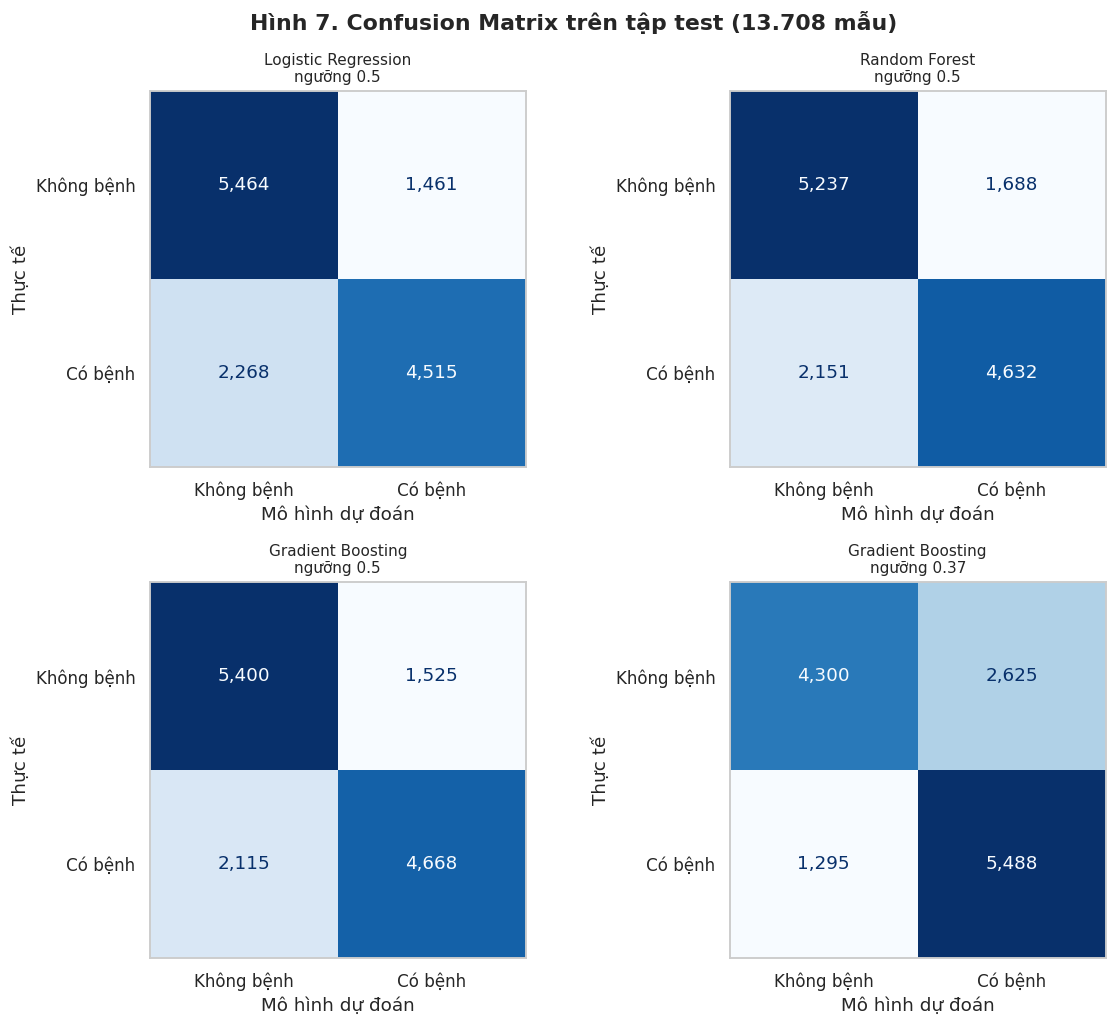

Báo cáo phân loại của Gradient Boosting ở ngưỡng 0.37:
              precision    recall  f1-score   support

  Không bệnh     0.7685    0.6209    0.6869      6925
     Có bệnh     0.6764    0.8091    0.7368      6783

    accuracy                         0.7140     13708
   macro avg     0.7225    0.7150    0.7119     13708
weighted avg     0.7230    0.7140    0.7116     13708



In [ ]:
panels = [(name, test_proba[name], 0.5) for name in fitted]
panels.append((CHOSEN, test_proba[CHOSEN], THRESHOLD))

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for ax, (name, proba, threshold) in zip(axes.ravel(), panels):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (proba >= threshold).astype(int), display_labels=["Không bệnh", "Có bệnh"],
        cmap="Blues", values_format=",", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nngưỡng {threshold}", fontsize=10)
    ax.set(xlabel="Mô hình dự đoán", ylabel="Thực tế")
    ax.grid(False)
fig.suptitle("Hình 7. Confusion Matrix trên tập test (13.708 mẫu)", fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Báo cáo phân loại của {CHOSEN} ở ngưỡng {THRESHOLD}:")
print(classification_report(y_test, (test_proba[CHOSEN] >= THRESHOLD).astype(int),
                            target_names=["Không bệnh", "Có bệnh"], digits=4))

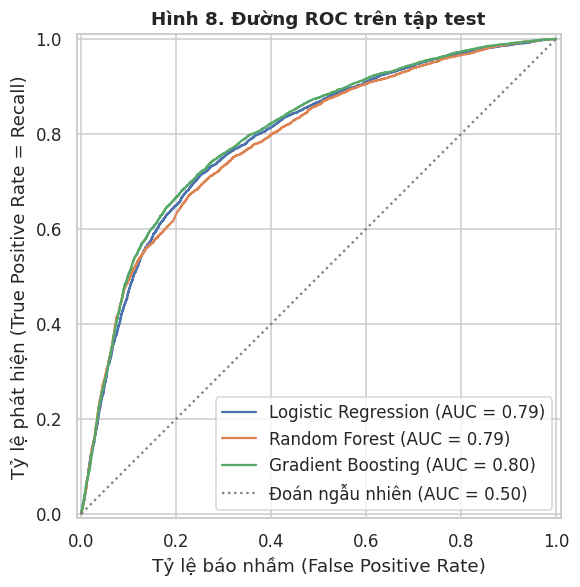

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, proba in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Đoán ngẫu nhiên (AUC = 0.50)")
ax.set(xlabel="Tỷ lệ báo nhầm (False Positive Rate)",
       ylabel="Tỷ lệ phát hiện (True Positive Rate = Recall)")
ax.set_title("Hình 8. Đường ROC trên tập test", fontweight="bold")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Nhận xét:**

- Ở ngưỡng 0,5, Gradient Boosting vẫn dẫn đầu trên tập test (F1 0,7195), Logistic Regression (0,7077) và Random Forest (0,7070) gần bằng nhau. F1 test chênh F1 kiểm định chéo không quá 0,2 điểm phần trăm ở cả 3 mô hình, nên kết quả kiểm định chéo đáng tin.
- Gradient Boosting ở ngưỡng 0,37 đạt trên tập test: Accuracy 0,7140, Precision 0,6764, **Recall 0,8091**, **F1 0,7368**, ROC-AUC 0,8000. Các số này gần với kết quả trên train ở mục 5 (Recall 0,8046, F1 0,7370), nên ngưỡng chọn từ train vẫn đúng với dữ liệu mới. Accuracy giảm từ 0,7345 xuống 0,7140 vì mô hình báo nhầm nhiều người khỏe hơn.
- Hình 7: khi hạ ngưỡng từ 0,5 xuống 0,37, số người có bệnh bị bỏ sót (ô dưới bên trái) giảm từ 2.115 xuống 1.295. Đổi lại, số người khỏe bị báo nhầm (ô trên bên phải) tăng từ 1.525 lên 2.625.
- Hình 8: ba đường ROC gần trùng nhau, AUC từ 0,79 đến 0,80. Ba thuật toán rất khác nhau cùng dừng ở mức này, nên muốn tốt hơn nhiều thì cần thêm thông tin đầu vào (ví dụ chỉ số cholesterol thật thay vì 3 mức), không chỉ đổi thuật toán.
- Với Accuracy khoảng 0,71, mô hình chỉ phù hợp để sàng lọc và nhắc người dùng đi khám, không thay được chẩn đoán của bác sĩ.

## 7. Kiểm tra overfitting

So sánh F1 (ngưỡng 0,5) ở ba chỗ: trên chính tập train mô hình đã học, trung bình kiểm định chéo, và trên tập test. Ba số gần nhau nghĩa là mô hình không học thuộc dữ liệu và dùng được cho người mới.

In [ ]:
overfit = pd.DataFrame({
    "F1 train": {n: f1_score(y_train, m.predict(X_train)) for n, m in fitted.items()},
    "F1 kiểm định chéo": tuned["F1"],
    "F1 test": {n: f1_score(y_test, (p >= 0.5).astype(int)) for n, p in test_proba.items()},
})
overfit["Train - test (điểm %)"] = (overfit["F1 train"] - overfit["F1 test"]) * 100
overfit.round(4)

,F1 train,F1 kiểm định chéo,F1 test,Train - test (điểm %)
Logistic Regression,0.7079,0.7078,0.7077,0.0120
Random Forest,0.7080,0.7090,0.7070,0.0981
Gradient Boosting,0.7211,0.7186,0.7195,0.1591


**Nhận xét:** sau tinh chỉnh, F1 train cao hơn F1 test dưới 1 điểm phần trăm ở cả 3 mô hình (Gradient Boosting 0,16 điểm, Random Forest 0,10 điểm, Logistic Regression 0,01 điểm). Trước tinh chỉnh, Random Forest chênh gần 30 điểm (mục 2). Cả 3 mô hình đã tinh chỉnh đều không bị overfitting.

## 8. Feature Importance

Nhóm dùng **permutation importance** trên tập test: xáo trộn ngẫu nhiên giá trị của một đặc trưng (10 lần) rồi đo ROC-AUC giảm bao nhiêu. Đặc trưng càng quan trọng thì xáo trộn nó làm điểm giảm càng nhiều. Cách này áp dụng được cho cả 3 mô hình, nên so sánh được với nhau.

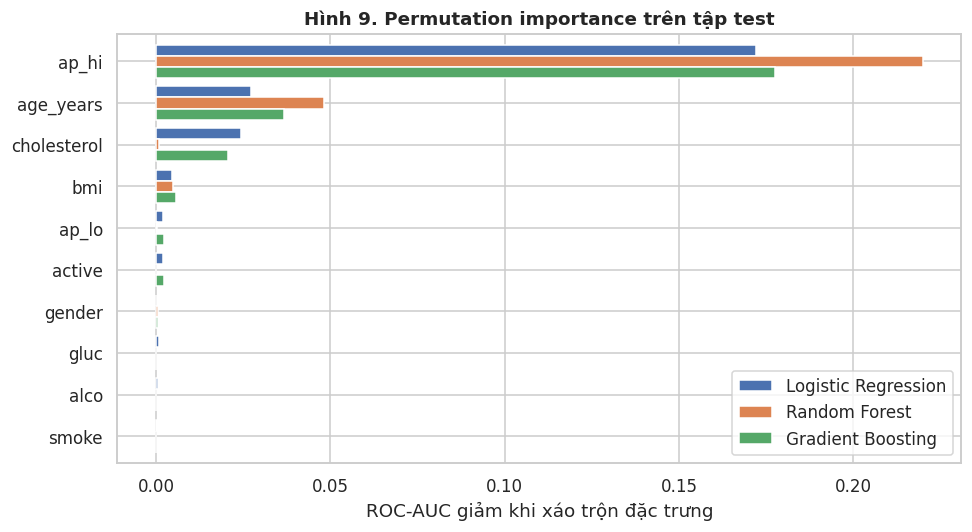

,Logistic Regression,Random Forest,Gradient Boosting
ap_hi,0.1720,0.2200,0.1775
age_years,0.0272,0.0483,0.0367
cholesterol,0.0244,0.0008,0.0205
bmi,0.0046,0.0048,0.0058
ap_lo,0.0021,0.0004,0.0024
active,0.0021,0.0000,0.0022
gender,0.0001,0.0006,0.0004
gluc,0.0009,0.0000,0.0001
alco,0.0006,-0.0000,-0.0000
smoke,0.0004,-0.0000,-0.0001


In [ ]:
importances = {}
for name, model in fitted.items():
    result = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    importances[name] = pd.Series(result.importances_mean, index=FEATURES)
importance_table = pd.DataFrame(importances).sort_values(CHOSEN, ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
importance_table.plot.barh(ax=ax, width=0.8)
ax.invert_yaxis()
ax.set(xlabel="ROC-AUC giảm khi xáo trộn đặc trưng", ylabel="")
ax.set_title("Hình 9. Permutation importance trên tập test", fontweight="bold")
fig.tight_layout()
plt.show()
importance_table.round(4)

Hệ số của Logistic Regression cho biết thêm **hướng** tác động. Vì dữ liệu đã được chuẩn hóa, mỗi hệ số là mức thay đổi log-odds khi đặc trưng tăng 1 độ lệch chuẩn (với cột nhị phân là khi đổi từ 0 sang 1, tính theo thang đã chuẩn hóa). `exp(hệ số)` là tỷ số odds: lớn hơn 1 là tăng nguy cơ, nhỏ hơn 1 là giảm nguy cơ.

In [ ]:
logreg = fitted["Logistic Regression"].named_steps["logisticregression"]
pd.DataFrame({"Hệ số": logreg.coef_[0], "Tỷ số odds": np.exp(logreg.coef_[0])},
             index=FEATURES).sort_values("Hệ số", ascending=False).round(3)

,Hệ số,Tỷ số odds
ap_hi,0.940,2.560
age_years,0.341,1.407
cholesterol,0.337,1.401
bmi,0.139,1.149
ap_lo,0.108,1.114
gender,0.013,1.013
alco,-0.041,0.960
smoke,-0.042,0.959
gluc,-0.067,0.935
active,-0.091,0.913


**Nhận xét:**

- Cả 3 mô hình xếp huyết áp tâm thu `ap_hi` quan trọng nhất (xáo trộn cột này làm ROC-AUC của Gradient Boosting giảm 0,178), tiếp theo là tuổi (0,037). Cholesterol đứng thứ ba ở Gradient Boosting (0,021) và Logistic Regression (0,024). Mỗi đặc trưng còn lại chỉ làm ROC-AUC giảm dưới 0,006. Thứ tự này khớp với Hình 3 và Hình 5 của bài nghiệm thu.
- `ap_lo` tương quan với nhãn 0,34 (Hình 5 của bài nghiệm thu) nhưng importance thấp. Lý do là `ap_lo` tương quan 0,74 với `ap_hi`: khi xáo trộn `ap_lo`, mô hình vẫn lấy được gần hết thông tin đó từ `ap_hi`.
- Theo hệ số Logistic Regression, huyết áp tâm thu tăng 1 độ lệch chuẩn (khoảng 17 mmHg) thì odds có bệnh tăng 2,56 lần. Tuổi tăng 1 độ lệch chuẩn (khoảng 6,8 năm) hoặc cholesterol tăng 1 độ lệch chuẩn thì odds tăng khoảng 1,4 lần. `active` có tỷ số odds 0,91: người có vận động thể lực có nguy cơ thấp hơn.
- `smoke`, `alco` và `gluc` có hệ số âm nhỏ. Với `smoke` và `alco`, đây là dấu hiệu dữ liệu tự khai bị thiếu đã nêu ở mục 1.5 của bài nghiệm thu. Với `gluc`, hệ số âm xuất hiện khi mô hình đã có `cholesterol` (hai cột tương quan 0,45), nên không có nghĩa đường huyết cao làm giảm nguy cơ. Ở hai mô hình cây, ràng buộc đơn điệu không cho các cột này làm giảm nguy cơ, nên importance của chúng gần 0.

## 9. Kiểm tra xác suất dự đoán (calibration)

Ứng dụng sẽ hiển thị xác suất dưới dạng "% nguy cơ", nên xác suất phải sát với thực tế: trong nhóm người được dự đoán 70%, khoảng 70% phải thật sự có bệnh. Đường càng gần đường chéo thì xác suất càng đáng tin. Brier score là trung bình bình phương sai lệch giữa xác suất và nhãn thật, càng nhỏ càng tốt.

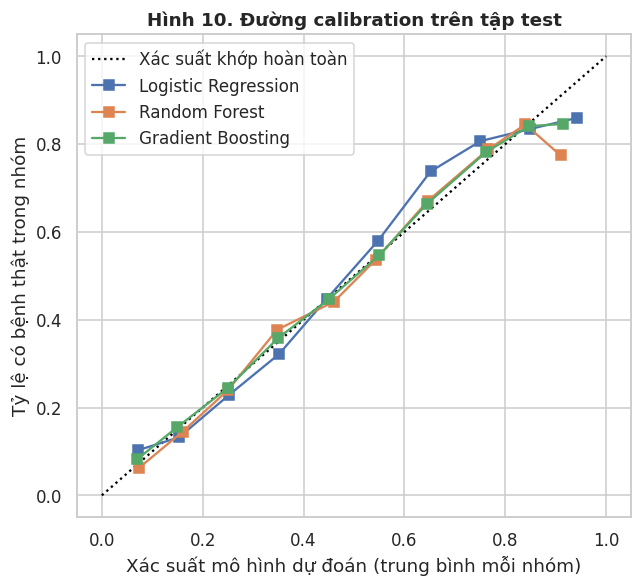

,Brier score
Logistic Regression,0.1867
Random Forest,0.1870
Gradient Boosting,0.1808


In [ ]:
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], color="black", linestyle=":", label="Xác suất khớp hoàn toàn")
for name, proba in test_proba.items():
    CalibrationDisplay.from_predictions(y_test, proba, n_bins=10, name=name, ref_line=False,
                                        ax=ax)
ax.set(xlabel="Xác suất mô hình dự đoán (trung bình mỗi nhóm)",
       ylabel="Tỷ lệ có bệnh thật trong nhóm")
ax.set_title("Hình 10. Đường calibration trên tập test", fontweight="bold")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

pd.Series({name: brier_score_loss(y_test, proba) for name, proba in test_proba.items()},
          name="Brier score").round(4).to_frame()

**Nhận xét:** đường của Gradient Boosting bám sát đường chéo từ 0,1 đến 0,85 (lệch không quá 0,02) và có Brier score thấp nhất (0,1808). Random Forest và Logistic Regression có Brier 0,1870 và 0,1867. Gradient Boosting chỉ lệch ở nhóm xác suất trên 0,9: mô hình dự đoán trung bình 0,92 nhưng tỷ lệ thật là 0,85, và nhóm này chỉ có 214 trong 13.708 mẫu test. Vì vậy ứng dụng hiển thị thẳng xác suất của Gradient Boosting dưới dạng "% nguy cơ" mà không cần hiệu chỉnh thêm.

## 10. Kiểm tra hướng tác động (ràng buộc đơn điệu)

Ứng dụng có bảng "Nếu cải thiện chỉ số": đưa từng chỉ số vượt mức khuyến cáo về mức nên đạt rồi tính lại nguy cơ. Mô hình chỉ học tương quan, nên nếu không ràng buộc, có người sẽ thấy chỉ số tốt lên mà nguy cơ lại tăng. Ô dưới đây huấn luyện lại mô hình đã chọn với cùng tham số nhưng bỏ ràng buộc. Sau đó, với từng chỉ số, ô này đếm trên tập test số người bị báo nguy cơ tăng từ 1 điểm % trở lên khi chỉ số đó về mức nên đạt: huyết áp dưới 120/80, BMI 24,9, cholesterol và đường huyết bình thường.


In [ ]:
from sklearn.base import clone

TARGETS = {"Huyết áp": {"ap_hi": 119, "ap_lo": 79}, "BMI": {"bmi": 24.9},
           "Cholesterol": {"cholesterol": 1}, "Đường huyết": {"gluc": 1}}


def wrong_direction(model, X: pd.DataFrame) -> Dict[str, str]:
    """Đếm người bị báo nguy cơ tăng từ 1 điểm % khi một chỉ số về mức nên đạt."""
    base = model.predict_proba(X)[:, 1]
    counts = {}
    for name, target in TARGETS.items():
        changed = X.copy()
        above = np.zeros(len(X), dtype=bool)
        for col, value in target.items():
            above |= (X[col] > value).to_numpy()
            changed[col] = np.minimum(X[col], value)
        rise = model.predict_proba(changed)[:, 1] - base >= 0.01
        counts[name] = f"{int(rise[above].sum())}/{int(above.sum())}"
    return counts


free_model = clone(best_model).set_params(monotonic_cst=None).fit(X_train, y_train)
direction = {}
compared = {"Không ràng buộc": free_model, "Có ràng buộc (mô hình chọn)": best_model}
for name, model in compared.items():
    proba = model.predict_proba(X_test)[:, 1]
    row = {"ROC-AUC": roc_auc_score(y_test, proba),
           f"F1 (ngưỡng {THRESHOLD})": f1_score(y_test, proba >= THRESHOLD)}
    row.update(wrong_direction(model, X_test))
    direction[name] = row
direction_table = pd.DataFrame(direction).T
direction_table.round(4)


,ROC-AUC,F1 (ngưỡng 0.37),Huyết áp,BMI,Cholesterol,Đường huyết
Không ràng buộc,0.801737,0.737856,56/11789,1616/8515,128/3481,1233/2110
Có ràng buộc (mô hình chọn),0.799973,0.736842,0/11789,0/8515,0/3481,0/2110


**Nhận xét:**

- Không ràng buộc, mô hình báo ngược hướng cho nhiều người. Với đường huyết, 1.233 trên 2.110 người (58%) sẽ thấy chỉ số về bình thường mà nguy cơ lại tăng từ 1 điểm % trở lên. Với BMI là 1.616 trên 8.515 người (19%), cholesterol 128 trên 3.481 người, huyết áp 56 trên 11.789 người. Nguyên nhân là dữ liệu có những quan hệ ngược y khoa (mục 8: hệ số `gluc` của Logistic Regression âm), và mô hình học theo tương quan đó.
- Có ràng buộc, số ca báo ngược về 0 ở cả 4 chỉ số. ROC-AUC chỉ giảm 0,0017 (từ 0,8017 xuống 0,8000) và F1 giảm 0,0011 (từ 0,7379 xuống 0,7368).
- Nhóm giữ mô hình có ràng buộc: độ chính xác gần như không đổi, còn bảng "Nếu cải thiện chỉ số" của ứng dụng luôn đúng hướng y khoa.

## 11. Lưu mô hình cho ứng dụng

Nhóm lưu mô hình được chọn (đã huấn luyện trên toàn bộ tập train) vào `models/heart_model.joblib`, kèm `models/model_info.json` ghi danh sách đặc trưng, ràng buộc đơn điệu, ngưỡng cảnh báo, điểm test, confusion matrix, feature importance, khoảng tuổi của tập train và phiên bản thư viện. Ứng dụng đọc ngưỡng từ file JSON này, nên khi huấn luyện lại thì ứng dụng tự dùng ngưỡng mới.

In [ ]:
model_path = MODEL_DIR / "heart_model.joblib"
info_path = MODEL_DIR / "model_info.json"
chosen_row = test_table.loc[f"{CHOSEN} (ngưỡng {THRESHOLD})"]
model_info = {
    "model": CHOSEN,
    "params": {k: v for k, v in searches[CHOSEN].best_params_.items()},
    "features": FEATURES,
    "monotonic_cst": MONOTONIC,
    "threshold": THRESHOLD,
    "n_trees": int(getattr(best_model, "n_iter_", 0)),  # số cây thực tế sau early stopping
    "train_rows": len(X_train),
    "test_rows": len(X_test),
    "cv_f1": round(float(tuned.loc[CHOSEN, "F1"]), 4),
    "test_metrics": {k: round(float(v), 4) for k, v in chosen_row.items()},
    # Ứng dụng đọc 3 mục dưới đây để hiển thị, không phải tính lại
    "confusion_matrix": dict(zip(["tn", "fp", "fn", "tp"], confusion_matrix(
        y_test, (test_proba[CHOSEN] >= THRESHOLD).astype(int)).ravel().tolist())),
    "feature_importance": importance_table[CHOSEN].round(4).to_dict(),
    "age_range": [float(X_train["age_years"].min()), float(X_train["age_years"].max())],
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
    "trained_on": date.today().isoformat(),
}

try:
    MODEL_DIR.mkdir(exist_ok=True)
    joblib.dump(best_model, model_path, compress=3)
    info_path.write_text(json.dumps(model_info, ensure_ascii=False, indent=2), encoding="utf-8")
except OSError as err:
    print(f"Không lưu được mô hình: {err}")
else:
    # Nạp lại file vừa lưu, kiểm tra dự đoán có khớp mô hình đang chạy không
    reloaded = joblib.load(model_path)
    same = np.allclose(reloaded.predict_proba(X_test)[:, 1], test_proba[CHOSEN])
    print(f"Đã lưu {model_path.relative_to(ROOT)} ({model_path.stat().st_size / 2**20:.2f} MB)")
    print(f"Đã lưu {info_path.relative_to(ROOT)}")
    print(f"Nạp lại cho cùng kết quả: {same}")
    print(json.dumps(model_info, ensure_ascii=False, indent=2))

Đã lưu models/heart_model.joblib (0.12 MB)
Đã lưu models/model_info.json
Nạp lại cho cùng kết quả: True
{
  "model": "Gradient Boosting",
  "params": {
    "min_samples_leaf": 50,
    "max_leaf_nodes": 63,
    "max_iter": 100,
    "max_depth": 6,
    "learning_rate": 0.1,
    "l2_regularization": 1.0
  },
  "features": [
    "age_years",
    "gender",
    "bmi",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
  ],
  "monotonic_cst": {
    "age_years": 1,
    "gender": 0,
    "bmi": 1,
    "ap_hi": 1,
    "ap_lo": 1,
    "cholesterol": 1,
    "gluc": 1,
    "smoke": 1,
    "alco": 1,
    "active": -1
  },
  "threshold": 0.37,
  "n_trees": 99,
  "train_rows": 54831,
  "test_rows": 13708,
  "cv_f1": 0.7186,
  "test_metrics": {
    "Accuracy": 0.714,
    "Precision": 0.6764,
    "Recall": 0.8091,
    "F1": 0.7368,
    "Tỷ lệ bị báo có nguy cơ": 0.5918,
    "ROC-AUC": 0.8
  },
  "confusion_matrix": {
    "tn": 4300,
    "fp": 2625,
    "fn": 12

## Tóm tắt

- Dữ liệu: 68.539 mẫu sạch, train 54.831, test 13.708, cùng cách chia với bài nghiệm thu.
- Tinh chỉnh siêu tham số sửa được overfitting của Random Forest: F1 train giảm từ 0,987 xuống 0,708, F1 kiểm định chéo tăng từ 0,693 lên 0,709.
- Mô hình được chọn: Gradient Boosting (`HistGradientBoostingClassifier`, 99 cây, mỗi cây tối đa 63 lá) có ràng buộc đơn điệu theo hướng y khoa, ngưỡng cảnh báo 0,37.
- Kết quả trên tập test: Accuracy 0,714, Precision 0,676, Recall 0,809, F1 0,737, ROC-AUC 0,800.
- Ràng buộc đơn điệu đưa số ca "chỉ số tốt lên mà nguy cơ tăng" về 0, đổi lại ROC-AUC chỉ giảm 0,002.
- Ba yếu tố quan trọng nhất: huyết áp tâm thu, tuổi, cholesterol.
- File cho ứng dụng: `models/heart_model.joblib` (0,12 MB) và `models/model_info.json`.